In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

In [2]:
housing = fetch_california_housing(as_frame = True)
df = housing.frame

In [3]:
df.shape

(20640, 9)

In [4]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [6]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [7]:
df.isna().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [8]:
df.duplicated().sum()

0

In [9]:
# Feature Relationships

df.corr()['MedHouseVal'].sort_values(ascending = False)

MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64

In [10]:
#target distribution
df['MedHouseVal'].describe()

count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64

In [11]:
x = df.drop(columns = ['MedHouseVal'])
y = df['MedHouseVal']

print(x.shape)
print(y.shape)

(20640, 8)
(20640,)


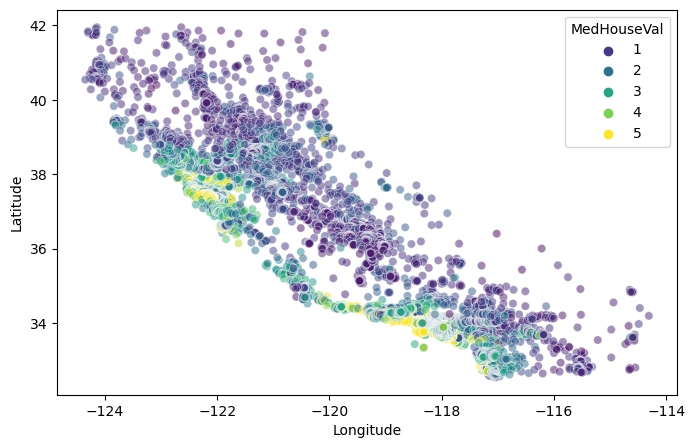

In [12]:
# Checking for Location relative to med house value
plt.figure(figsize = (8, 5))

sns.scatterplot(
    data = df,
    x = 'Longitude',
    y = 'Latitude',
    hue = 'MedHouseVal',
    palette = 'viridis',
    alpha = 0.5
)

plt.show();

In [13]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 10)

In [14]:
x_train.shape, x_test.shape

((16512, 8), (4128, 8))

### Modelling

In [15]:
# Establishing baseline
from sklearn.dummy import DummyRegressor


In [16]:
dummy = DummyRegressor(strategy = 'mean')
dummy.fit(x_train, y_train)
y_dummy = dummy.predict(x_test)

In [17]:
#Evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print('MAE: ', mean_absolute_error(y_test, y_dummy))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, y_dummy)))
print('R2: ', r2_score(y_test, y_dummy))

MAE:  0.92412132342939
RMSE:  1.1683106840224897
R2:  -0.00029279839472251545


In [19]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(x_train, y_train)

y_lr = lr.predict(x_test)

In [20]:
print('MAE: ', mean_absolute_error(y_test, y_lr))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, y_lr)))
print('R2: ', r2_score(y_test, y_lr))

MAE:  0.5366527228153415
RMSE:  0.737891734750625
R2:  0.6009790143129111


In [22]:
#Random Forest
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators = 100,
    random_state = 10,
    n_jobs = -1
)

rf.fit(x_train, y_train)
y_rf = rf.predict(x_test)

In [27]:
print('MAE: ', mean_absolute_error(y_test, y_rf))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, y_rf)))
print('R2: ', r2_score(y_test, y_rf))

MAE:  0.7306595242233147
RMSE:  1.047352370139792
R2:  0.19611100142880367


In [28]:
# verify if rf is overfitting

y_trf = rf.predict(x_train)

print('Train R2: ', r2_score(y_train, y_trf))
print('Test R2: ', r2_score(y_test, y_rf))

Train R2:  0.9734167917580264
Test R2:  0.19611100142880367


above implies a clear case of overfitting

In [29]:
# addressing overfitting by parameter tuning
rf_tuned = RandomForestRegressor(
    n_estimators=100,
    max_depth = 15,
    min_samples_split= 10,
    min_samples_leaf=5,
    random_state = 10,
    n_jobs = -1
)

rf_tuned.fit(x_train, y_train)

y_ptune = rf_tuned.predict(x_test)

In [30]:
print('MAE: ', mean_absolute_error(y_test, y_ptune))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, y_ptune)))
print('R2 Score: ', r2_score(y_test, y_ptune))

MAE:  0.3315266819100814
RMSE:  0.5162972853994782
R2 Score:  0.8046514784140221


In [31]:
#verifying tuning reduced overfitting
y_ttune = rf_tuned.predict(x_train)
print('Train R2: ', r2_score(y_train, y_ttune))
print('Test R2: ', r2_score(y_test, y_ptune))

Train R2:  0.9077900294914478
Test R2:  0.8046514784140221


some overfitting exists but our model perfomrs better on unseen data

In [32]:
# feature importance
importance = pd.Series(
    rf_tuned.feature_importances_, index = x.columns
).sort_values(ascending = False)

print(importance)

MedInc        0.563106
AveOccup      0.136141
Longitude     0.089810
Latitude      0.086268
HouseAge      0.048904
AveRooms      0.037858
AveBedrms     0.019236
Population    0.018676
dtype: float64


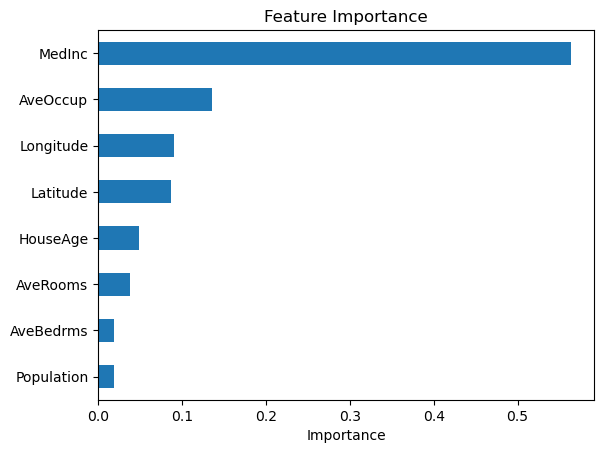

In [33]:
importance.sort_values().plot(kind = 'barh', title = 'Feature Importance')
plt.xlabel('Importance')
plt.show();

## Conclusion
This project developed regression models to predict median house values in California using demographic, housing and geographical features.
Four models were evaluated: DummyRegressor, Linear Regression, Random Forest Regressor and a tuned Random Forest Regressor.
The tuned Random Forest achieved the best performance, with an MAE of 0.33, RMSE of 0.51 and R² of 0.8046. This means the model explained approximately 80.46% of the variation in house values in the test dataset.
An important finding was that the original Random Forest showed substantial overfitting. Restricting tree complexity through hyperparameter adjustments improved its performance on unseen data.
Feature importance analysis identified median income ("MedInc") as the most influential predictor, followed by average occupancy ("AveOccup").
Overall, the project demonstrated that model selection and hyperparameter tuning are important in developing reliable regression models. However, the dataset has limitations, particularly the $500,000 cap on the target variable, which may reduce prediction reliability for higher-value properties.
